# Model Fitness: análisis de retención de clientes
## Proyecto del Sprint 14 — TripleTen

**Objetivo.** Identificar características asociadas con la cancelación, comparar dos modelos de clasificación para anticipar la pérdida de clientes el mes siguiente y describir cinco segmentos para orientar acciones de retención.

Se trabaja con el archivo original `gym_churn_us.csv` proporcionado para el proyecto. Cada fila representa un cliente. `Churn = 1` indica cancelación y `Churn = 0`, permanencia. Según el enunciado, las características corresponden a la información disponible antes del mes objetivo.

**Contenido:** 1. Carga y revisión · 2. Análisis exploratorio · 3. Clasificación · 4. Clustering · 5. Conclusiones y recomendaciones.

## 1. Carga y revisión de datos

Se conservan los nombres originales para facilitar la comparación con el diccionario del proyecto. El código busca primero el archivo en `/datasets/`, la ubicación habitual de TripleTen; también admite `/mnt/data/` y el mismo directorio del notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)

rutas = [Path('/datasets/gym_churn_us.csv'),
         Path('/mnt/data/gym_churn_us.csv'), Path('gym_churn_us.csv')]
ruta = next((p for p in rutas if p.is_file()), None)
if ruta is None:
    raise FileNotFoundError('Coloca gym_churn_us.csv junto al notebook o en /datasets/.')
gym = pd.read_csv(ruta)
print('Filas y columnas:', gym.shape)
display(gym.head())

Filas y columnas: (4000, 14)


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227,5.000,3,0.020,0.000,0
1,0,1,0,0,1,12,1,31,113.203,12.000,7,1.923,1.910,0
2,0,1,1,0,1,1,0,28,129.448,1.000,2,1.859,1.737,0
3,0,1,1,1,1,12,1,33,62.670,12.000,2,3.206,3.357,0
4,1,1,1,1,1,1,0,26,198.362,1.000,3,1.114,1.120,0


### Diccionario de variables

| Variable | Significado |
|---|---|
| `gender` | Género codificado; el enunciado no especifica la equivalencia de 0 y 1 |
| `Near_Location` | Vive o trabaja cerca del gimnasio |
| `Partner` | Trabaja en una empresa asociada |
| `Promo_friends` | Ingresó mediante la promoción de un amigo |
| `Phone` | Proporcionó un teléfono; no es el número telefónico |
| `Contract_period` | Duración del contrato en meses |
| `Group_visits` | Participa en actividades grupales |
| `Age` | Edad en años |
| `Avg_additional_charges_total` | Gasto acumulado en servicios adicionales; moneda no indicada |
| `Month_to_end_contract` | Meses restantes del contrato |
| `Lifetime` | Antigüedad como cliente, en meses |
| `Avg_class_frequency_total` | Promedio histórico de visitas por semana |
| `Avg_class_frequency_current_month` | Promedio semanal de visitas en el último mes de características |
| `Churn` | Cancelación del mes objetivo |

Las variables indicadoras toman valores 0 y 1.

In [2]:
gym.info()
revision = pd.DataFrame({
    'tipo': gym.dtypes.astype(str),
    'ausentes': gym.isna().sum(),
    'valores_distintos': gym.nunique()
})
display(revision)
print('Filas completamente duplicadas:', gym.duplicated().sum())
binarias = ['gender', 'Near_Location', 'Partner', 'Promo_friends',
            'Phone', 'Group_visits']
for col in binarias + ['Churn', 'Contract_period']:
    print(col, ':', sorted(gym[col].unique()))
print('Contratos con meses restantes mayores a su duración:',
      (gym['Month_to_end_contract'] > gym['Contract_period']).sum())

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

,tipo,ausentes,valores_distintos
gender,int64,0,2
Near_Location,int64,0,2
Partner,int64,0,2
Promo_friends,int64,0,2
Phone,int64,0,2
Contract_period,int64,0,3
Group_visits,int64,0,2
Age,int64,0,23
Avg_additional_charges_total,float64,0,4000
Month_to_end_contract,float64,0,12


Filas completamente duplicadas: 0
gender : [np.int64(0), np.int64(1)]
Near_Location : [np.int64(0), np.int64(1)]
Partner : [np.int64(0), np.int64(1)]
Promo_friends : [np.int64(0), np.int64(1)]
Phone : [np.int64(0), np.int64(1)]
Group_visits : [np.int64(0), np.int64(1)]
Churn : [np.int64(0), np.int64(1)]
Contract_period : [np.int64(1), np.int64(6), np.int64(12)]
Contratos con meses restantes mayores a su duración: 0


## 2. Análisis exploratorio de datos
### 2.1. Estadísticas descriptivas

En indicadores binarios, la media equivale a la proporción de clientes con valor 1. En las demás características se revisan media, desviación estándar, cuartiles y extremos.

In [3]:
display(gym.describe().T)
balance = gym['Churn'].value_counts().sort_index().to_frame('clientes')
balance['proporcion'] = balance['clientes'] / len(gym)
display(balance)

,count,mean,std,min,25%,50%,75%,max
gender,4000.000,0.510,0.500,0.000,0.000,1.000,1.000,1.000
Near_Location,4000.000,0.845,0.362,0.000,1.000,1.000,1.000,1.000
Partner,4000.000,0.487,0.500,0.000,0.000,0.000,1.000,1.000
Promo_friends,4000.000,0.308,0.462,0.000,0.000,0.000,1.000,1.000
Phone,4000.000,0.903,0.295,0.000,1.000,1.000,1.000,1.000
Contract_period,4000.000,4.681,4.550,1.000,1.000,1.000,6.000,12.000
Group_visits,4000.000,0.412,0.492,0.000,0.000,0.000,1.000,1.000
Age,4000.000,29.184,3.258,18.000,27.000,29.000,31.000,41.000
Avg_additional_charges_total,4000.000,146.944,96.356,0.148,68.869,136.220,210.950,552.591
Month_to_end_contract,4000.000,4.323,4.191,1.000,1.000,1.000,6.000,12.000


,clientes,proporcion
Churn,,
0,2939,0.735
1,1061,0.265


**Revisión.** El archivo contiene **4,000 clientes y 14 columnas**, sin valores ausentes ni filas completamente duplicadas. No se requiere imputación ni eliminación de registros. Los indicadores tienen valores 0 y 1. Se observan contratos de 1, 6 y 12 meses; aunque el diccionario menciona 3 meses, esa categoría no aparece en este archivo.

Cancelaron **1,061 clientes (26.53 %)** y permanecieron **2,939 (73.48 %)**. Este desbalance hace insuficiente evaluar solo accuracy. Los rangos y desviaciones estándar se revisan en la tabla; las características tienen escalas diferentes, por lo que se estandarizarán para regresión logística y clustering.

### 2.2. Medias de quienes permanecen y quienes cancelan

In [4]:
medias_churn = gym.groupby('Churn').mean().T
medias_churn.columns = ['Permanece (0)', 'Cancela (1)']
display(medias_churn)

,Permanece (0),Cancela (1)
gender,0.510,0.511
Near_Location,0.873,0.768
Partner,0.534,0.355
Promo_friends,0.354,0.184
Phone,0.904,0.903
Contract_period,5.747,1.729
Group_visits,0.464,0.269
Age,29.977,26.990
Avg_additional_charges_total,158.446,115.083
Month_to_end_contract,5.283,1.663


Quienes cancelan tienen una antigüedad media de **0.99 meses**, frente a **4.71** entre quienes permanecen. Su asistencia reciente es de **1.04 visitas semanales**, frente a **2.03**, y sus contratos duran en promedio **1.73 meses**, frente a **5.75**.

La participación grupal es menor entre quienes cancelan (**26.86 % frente a 46.41 %**). También tienen menor edad media (26.99 frente a 29.98 años) y menor gasto adicional (115.08 frente a 158.45). Género y teléfono muestran medias casi iguales. Estas diferencias describen asociaciones; no demuestran que modificar una característica cause retención.

### 2.3. Distribuciones por cancelación

Las barras muestran proporciones dentro de cada grupo para evitar que el mayor número de clientes que permanecen distorsione la comparación. Los histogramas usan densidad con normalización independiente. Se incluyen todas las características.

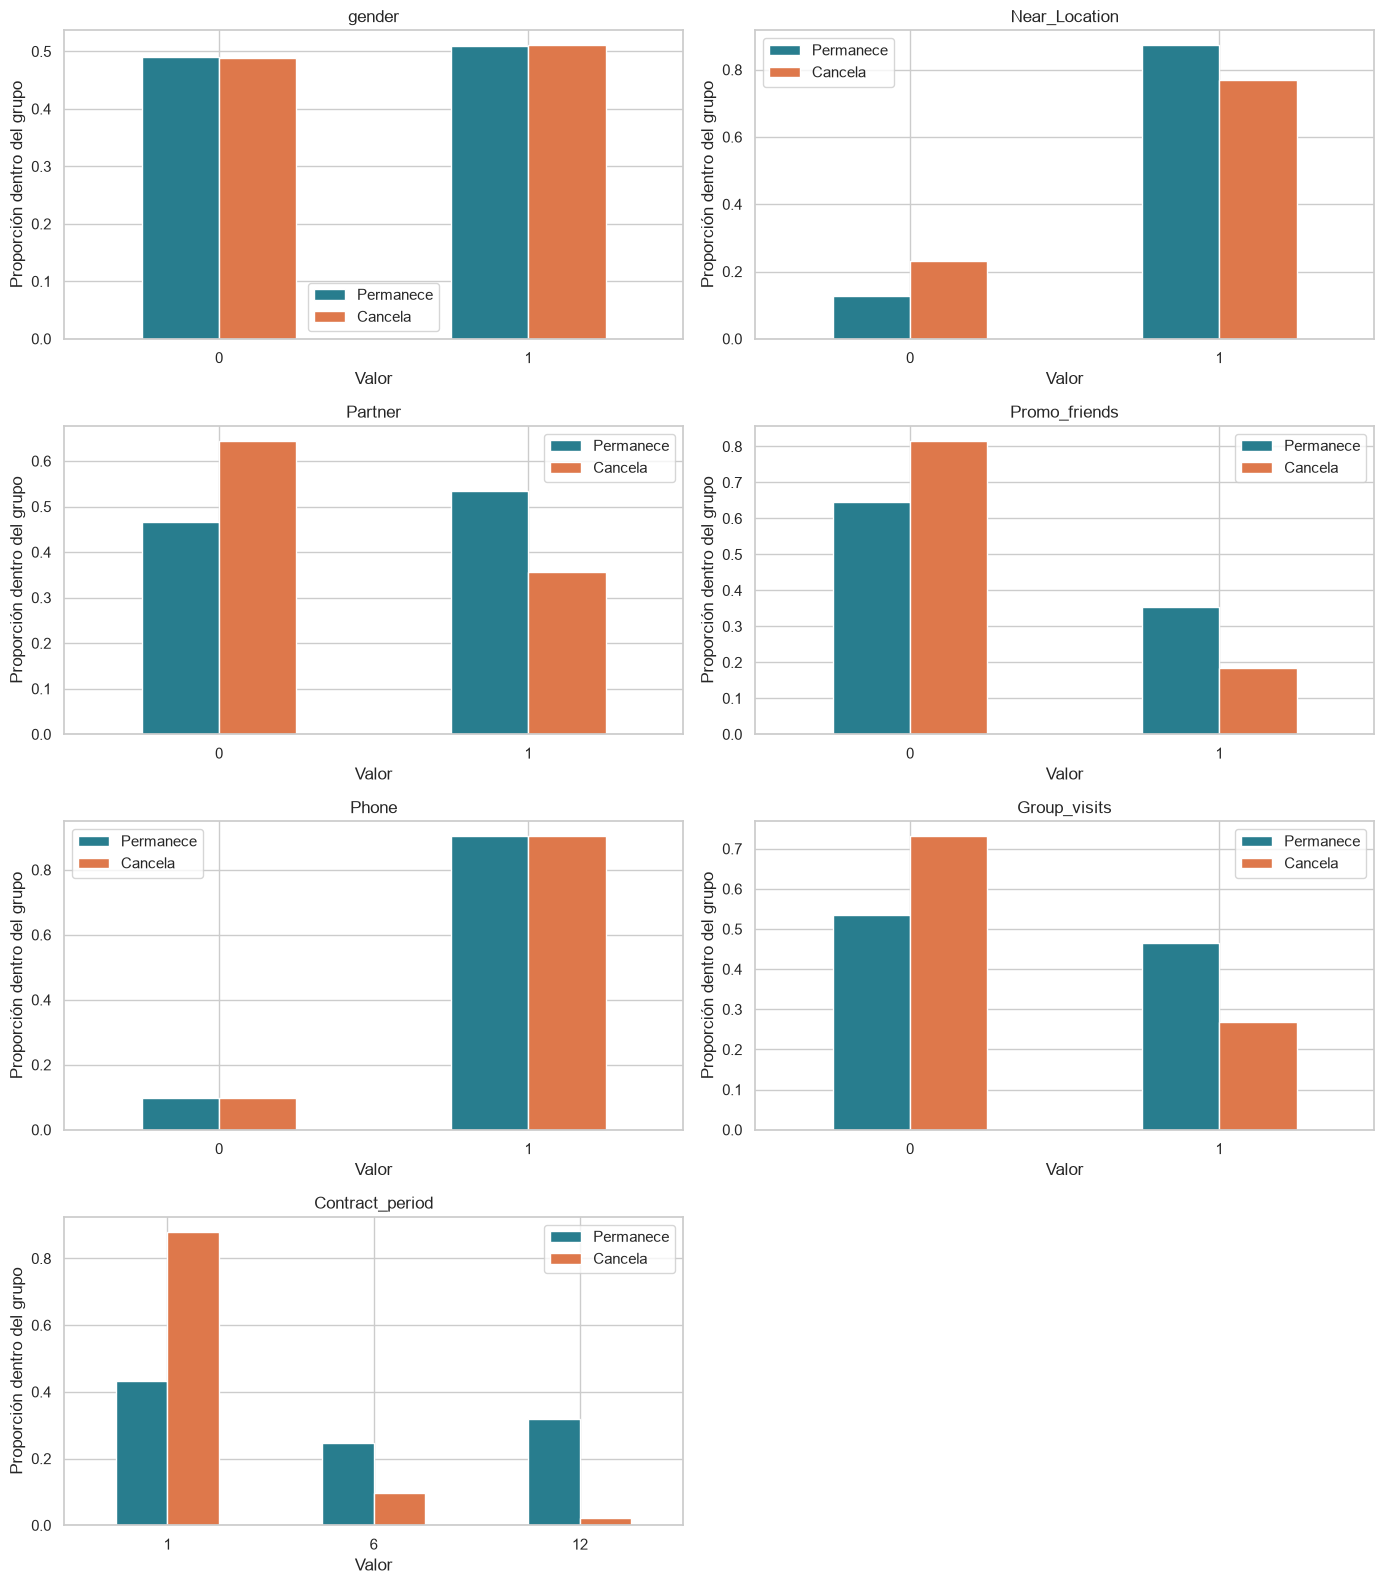

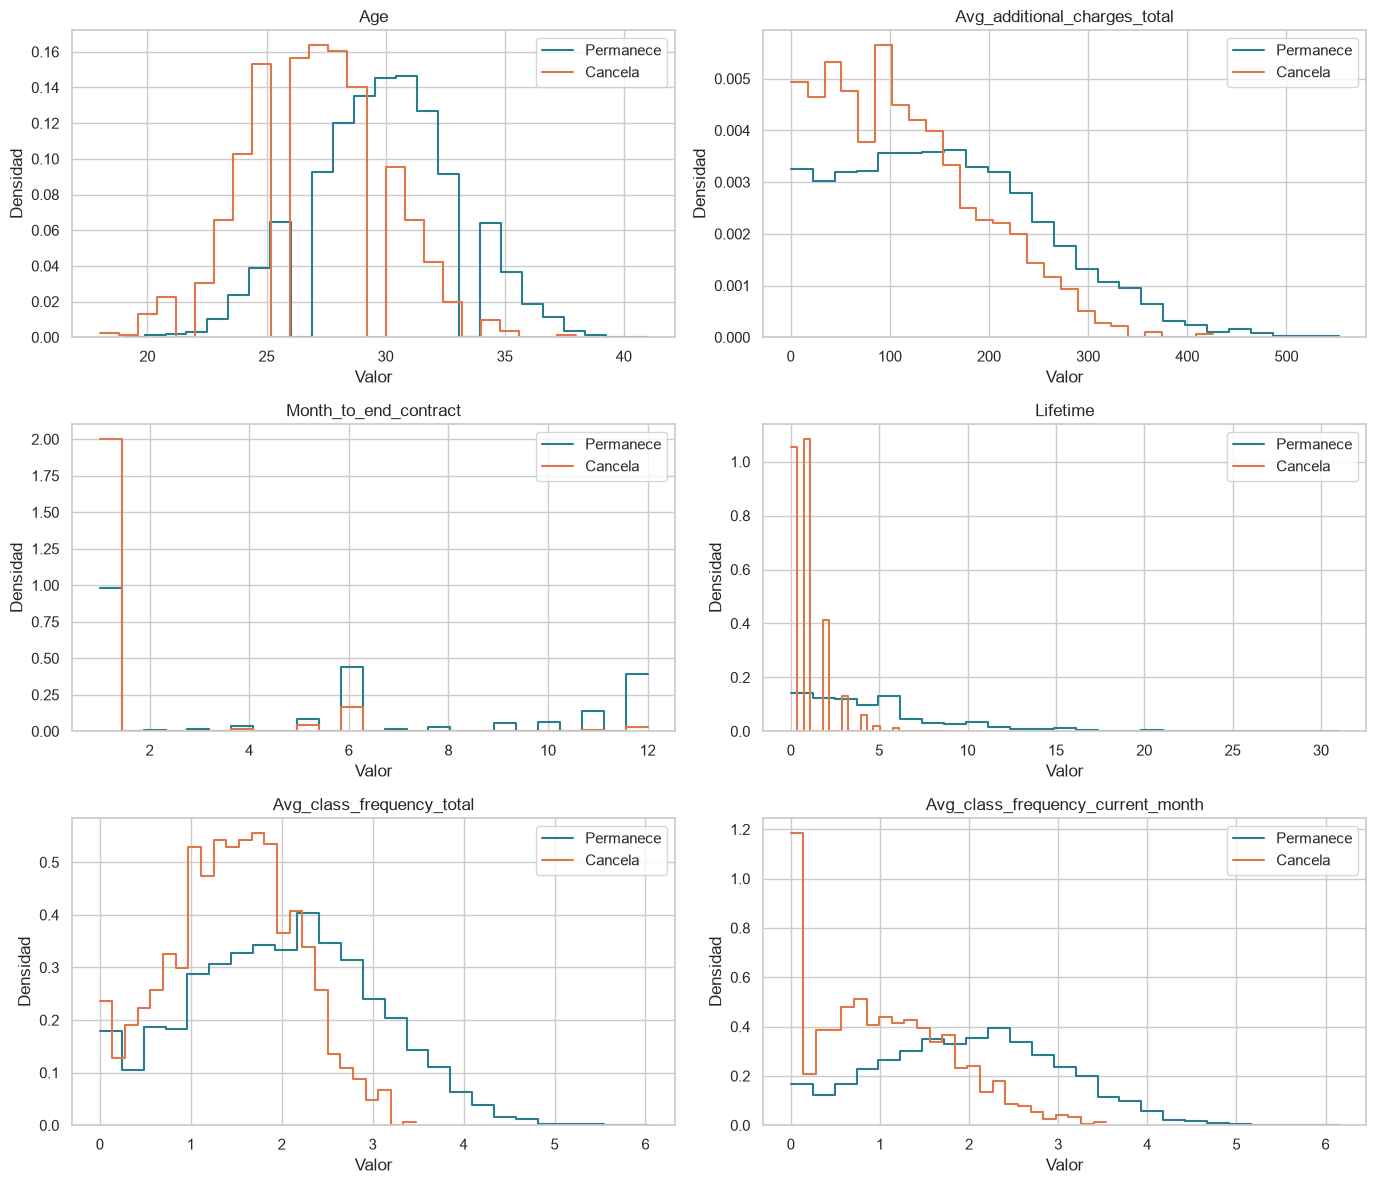

In [5]:
categoricas = binarias + ['Contract_period']
continuas = [col for col in gym.columns if col not in categoricas + ['Churn']]
colores_churn = ['#287D8E', '#DE784B']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.flat, categoricas):
    tabla = pd.crosstab(gym[col], gym['Churn'], normalize='columns')
    tabla.columns = ['Permanece', 'Cancela']
    tabla.plot.bar(ax=ax, color=colores_churn, rot=0)
    ax.set(title=col, xlabel='Valor', ylabel='Proporción dentro del grupo')
for ax in axes.flat[len(categoricas):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, col in zip(axes.flat, continuas):
    for estado, nombre, color in zip([0, 1], ['Permanece', 'Cancela'], colores_churn):
        sns.histplot(gym.loc[gym['Churn'] == estado, col],
                     bins=25, stat='density', element='step',
                     fill=False, color=color, label=nombre, ax=ax)
    ax.set(title=col, xlabel='Valor', ylabel='Densidad')
    ax.legend()
fig.tight_layout()
plt.show()

Las distribuciones permiten ver el solapamiento entre grupos: ninguna característica por sí sola separa perfectamente a quienes cancelan. La antigüedad, la asistencia reciente y la duración del contrato ayudan a distinguir sus perfiles. Las proporciones de género y disponibilidad de teléfono son parecidas entre ambos grupos.

### 2.4. Matriz de correlación

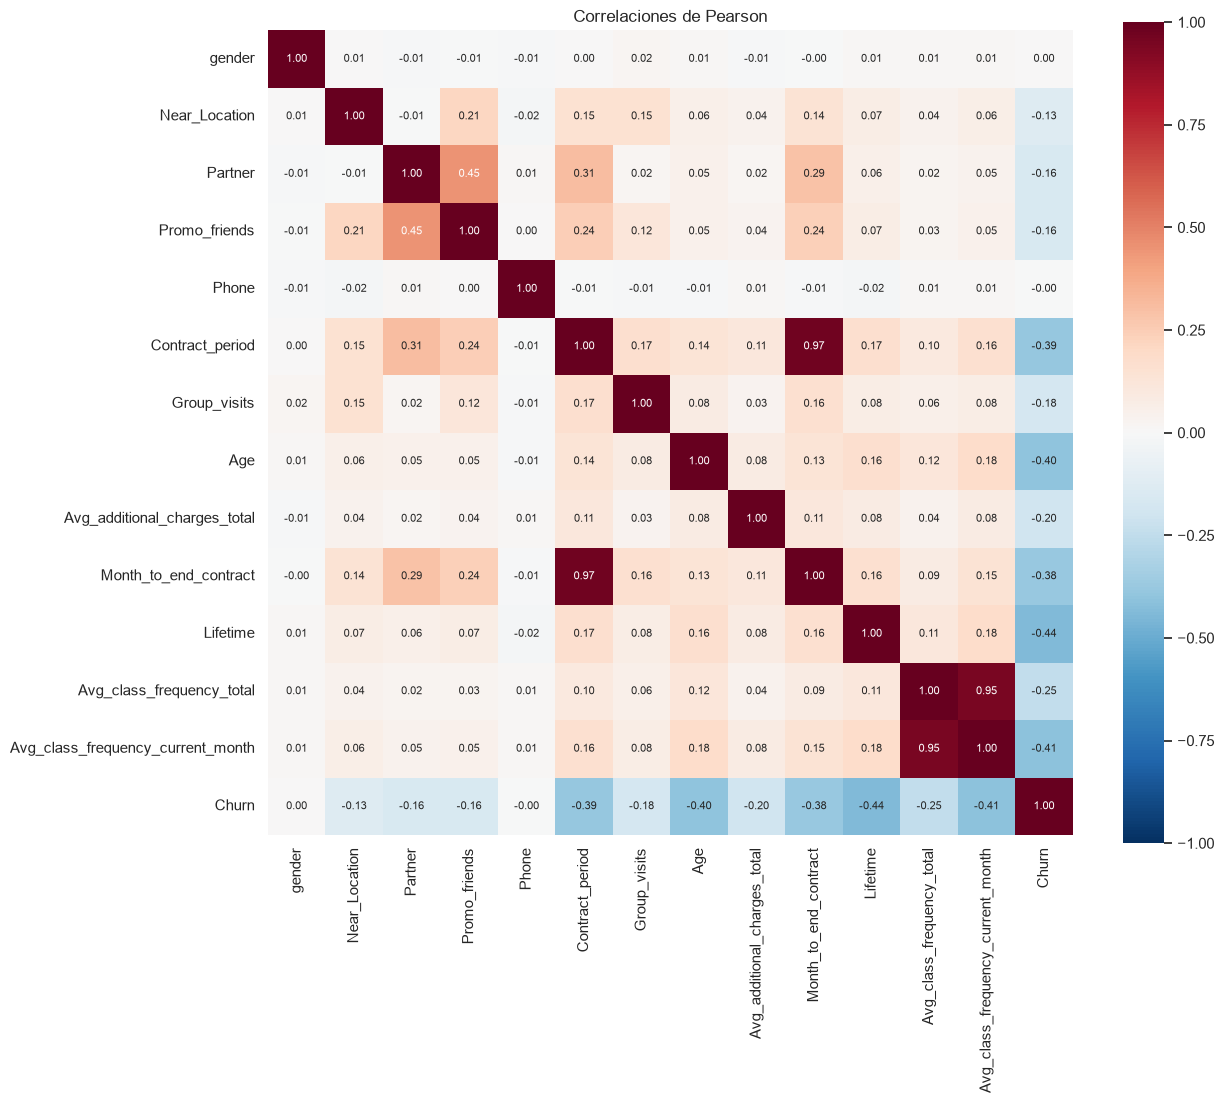

,correlacion_con_Churn
Lifetime,-0.438
Avg_class_frequency_current_month,-0.412
Age,-0.405
Contract_period,-0.390
Month_to_end_contract,-0.381
Avg_class_frequency_total,-0.250
Avg_additional_charges_total,-0.199
Group_visits,-0.175
Promo_friends,-0.162
Partner,-0.158


In [6]:
correlaciones = gym.corr()
plt.figure(figsize=(13, 11))
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            annot_kws={'size': 8})
plt.title('Correlaciones de Pearson')
plt.tight_layout()
plt.show()
display(correlaciones['Churn'].drop('Churn').sort_values().to_frame('correlacion_con_Churn'))

Las asociaciones negativas más fuertes con `Churn` corresponden a **Lifetime (−0.44)**, **asistencia reciente (−0.41)**, **Age (−0.40)** y **Contract_period (−0.39)**. Valores mayores se asocian con menor cancelación en este conjunto. Género y teléfono presentan correlaciones prácticamente nulas.

La duración del contrato y los meses restantes están fuertemente relacionados, al igual que las dos medidas de asistencia. Se conservan todas las características solicitadas para comparar los modelos y construir los segmentos; esta redundancia debe considerarse al interpretar coeficientes y distancias. La correlación mide asociación lineal y no permite establecer causalidad.

## 3. Modelo para predecir la cancelación
### 3.1. Separación de entrenamiento y validación

La variable objetivo es `Churn`. Se reserva un **20 %** para validación y se utiliza `stratify=y` para mantener la proporción de cancelaciones. `random_state=42` permite reproducir la división y los modelos.

La regresión logística recibe características estandarizadas. El escalador se ajusta **solo con entrenamiento** para evitar fuga de información. El bosque aleatorio utiliza los valores originales, porque los árboles no necesitan estandarización. Ambos se evalúan sobre los mismos clientes.

In [7]:
X = gym.drop(columns='Churn')
y = gym['Churn']
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
scaler_model = StandardScaler()
X_train_scaled = scaler_model.fit_transform(X_train)
X_valid_scaled = scaler_model.transform(X_valid)
print('Entrenamiento:', X_train.shape, '| Validación:', X_valid.shape)
print(f'Churn en entrenamiento: {y_train.mean():.2%}')
print(f'Churn en validación: {y_valid.mean():.2%}')

Entrenamiento: (3200, 13) | Validación: (800, 13)
Churn en entrenamiento: 26.53%
Churn en validación: 26.50%


### 3.2. Entrenamiento y métricas

- **Accuracy (exactitud):** proporción total de predicciones correctas.
- **Precision (precisión):** entre los clientes identificados como posibles cancelaciones, proporción que realmente cancela.
- **Recall (sensibilidad):** proporción de cancelaciones reales detectadas. Es especialmente relevante para no omitir clientes que necesitan atención.

La clase positiva es 1. Se usa la clasificación predeterminada de cada modelo, sin ajustar hiperparámetros sobre validación. Se incluye una referencia que predice permanencia para todos.

,accuracy,precision,recall
modelo,,,
Regresión logística,0.925,0.880,0.830
Bosque aleatorio,0.927,0.885,0.835
Siempre permanece,0.735,0.000,0.000


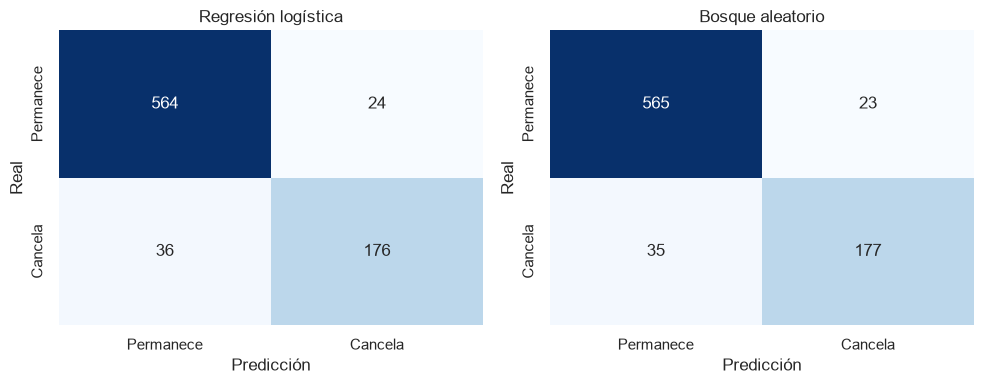

In [8]:
logistic_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
forest_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
logistic_model.fit(X_train_scaled, y_train)
forest_model.fit(X_train, y_train)

predicciones = {
    'Regresión logística': logistic_model.predict(X_valid_scaled),
    'Bosque aleatorio': forest_model.predict(X_valid),
    'Siempre permanece': np.zeros(len(y_valid), dtype=int)
}
resultados = []
for nombre, pred in predicciones.items():
    resultados.append({
        'modelo': nombre,
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred, zero_division=0)
    })
metricas = pd.DataFrame(resultados).set_index('modelo')
display(metricas.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre in zip(axes, ['Regresión logística', 'Bosque aleatorio']):
    sns.heatmap(confusion_matrix(y_valid, predicciones[nombre]),
                annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Permanece', 'Cancela'],
                yticklabels=['Permanece', 'Cancela'])
    ax.set(title=nombre, xlabel='Predicción', ylabel='Real')
plt.tight_layout()
plt.show()

**Comparación.** El bosque aleatorio obtiene accuracy de **0.9275**, precision de **0.8850** y recall de **0.8349**. La regresión logística alcanza **0.9250**, **0.8800** y **0.8302**, respectivamente.

En esta partición, el **bosque aleatorio es ligeramente mejor en las tres métricas** y se selecciona para ejemplificar la priorización por probabilidad. Detecta 177 de las 212 cancelaciones de validación, frente a 176 de la regresión logística. La diferencia es pequeña: solo dos aciertos totales más. No permite afirmar una superioridad general sin validación adicional.

La referencia que siempre predice permanencia tiene accuracy de 0.7350 y recall de 0: no detecta ninguna cancelación. Ambos modelos aportan una mejora clara frente a esa referencia. Para una aplicación futura convendría validar con meses posteriores y definir el umbral según la capacidad y el costo de la campaña.

### 3.3. Probabilidades individuales

Además de la clase, se obtiene la probabilidad estimada de cancelación con `predict_proba`. Se muestran clientes de validación, no usados en el entrenamiento. El índice identifica la fila original, ya que el archivo no contiene un identificador de cliente. Estas probabilidades permiten ordenar una campaña de contacto; no se ha evaluado su calibración.

In [9]:
probabilidades = pd.DataFrame({
    'churn_real': y_valid,
    'probabilidad_cancelacion': forest_model.predict_proba(X_valid)[:, 1],
    'prediccion': predicciones['Bosque aleatorio']
}).sort_values('probabilidad_cancelacion', ascending=False)
display(probabilidades.head(10))

,churn_real,probabilidad_cancelacion,prediccion
1414,1,1.000,1
2701,1,1.000,1
3140,1,1.000,1
3205,1,1.000,1
3108,1,0.990,1
221,1,0.990,1
2582,1,0.990,1
3870,1,0.990,1
3476,1,0.990,1
3533,1,0.990,1


## 4. Clustering de clientes
### 4.1. Estandarización y dendrograma

Se excluye `Churn` antes de construir los grupos. Se estandarizan las 13 características para que las diferencias de escala no dominen las distancias. Aquí se ajusta un escalador nuevo sobre todos los clientes porque el objetivo es describir la población disponible mediante aprendizaje no supervisado.

`linkage` construye la jerarquía con el método Ward y distancia euclídea. Se utilizan todos los registros. El dendrograma se muestra truncado a las últimas 30 ramas para facilitar su lectura; esto solo cambia la visualización, no el cálculo.

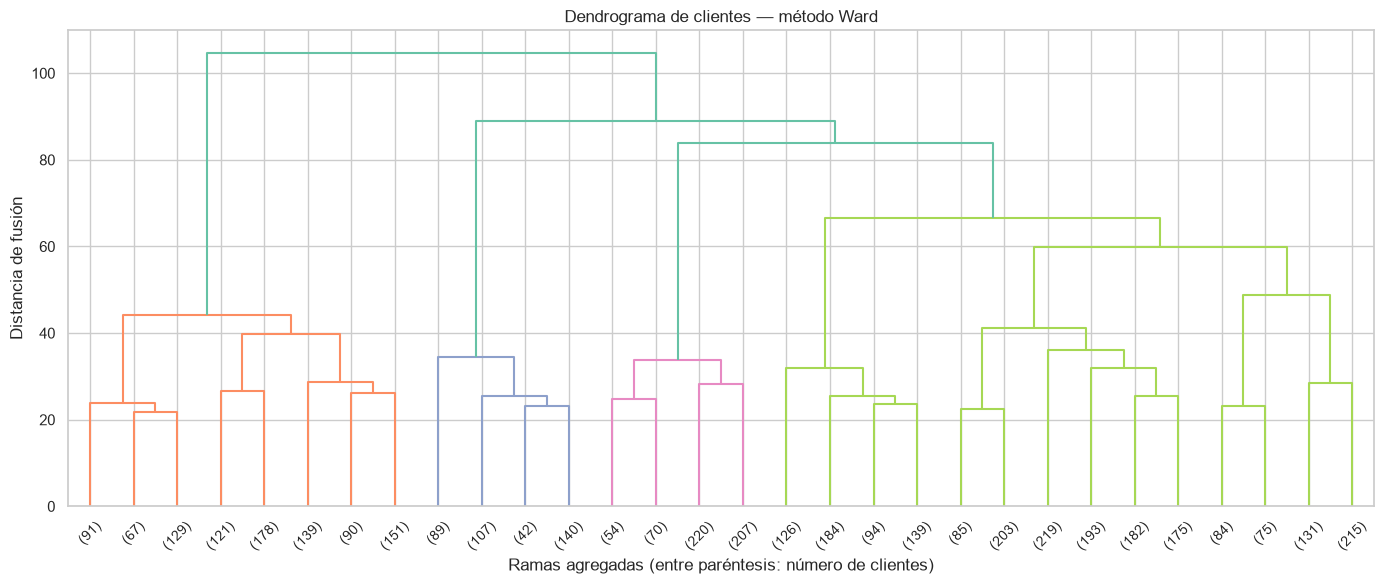

,distancia_fusion,clientes_fusionados
0,41.262,1057.000
1,44.155,966.000
2,48.695,505.000
3,59.910,1562.000
4,66.592,2105.000
5,83.873,2656.000
6,88.956,3034.000
7,104.628,4000.000


In [10]:
X_cluster = gym.drop(columns='Churn')
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)
linked = linkage(X_cluster_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(linked, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrograma de clientes — método Ward')
plt.xlabel('Ramas agregadas (entre paréntesis: número de clientes)')
plt.ylabel('Distancia de fusión')
plt.tight_layout()
plt.show()
display(pd.DataFrame(linked[-8:, 2:], columns=['distancia_fusion', 'clientes_fusionados']))

Las últimas fusiones se producen aproximadamente a distancias **59.9, 66.6, 83.9, 89.0 y 104.6**. Un corte entre 66.6 y 83.9 deja **cuatro grupos**, una opción visual razonable por el salto entre esas fusiones. Un corte entre 59.9 y 66.6 deja cinco. El dendrograma no determina una única solución óptima: depende del nivel de detalle buscado.

Se utilizarán **cinco clústeres** de K-Means para cumplir la consigna. Ward y K-Means son métodos diferentes, por lo que sus grupos no tienen por qué coincidir.

### 4.2. K-Means con cinco clústeres

Se fija `n_clusters=5` como solicita el proyecto y `n_init=10` para realizar diez inicializaciones y mantener este ajuste explícito entre versiones. Los números de clúster son etiquetas arbitrarias, no representan un orden de riesgo.

In [11]:
kmeans = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_cluster_scaled)
gym_cluster = gym.copy()
gym_cluster['cluster'] = clusters
medias_cluster = gym_cluster.groupby('cluster')[X_cluster.columns].mean()
display(medias_cluster.T)
print('Clientes por clúster:')
display(gym_cluster['cluster'].value_counts().sort_index().to_frame('clientes'))

cluster,0,1,2,3,4
gender,0.496,0.499,0.486,0.489,0.585
Near_Location,0.000,0.944,0.998,1.000,0.971
Partner,0.467,0.740,0.824,0.243,0.259
Promo_friends,0.077,0.485,1.000,0.021,0.090
Phone,0.915,0.901,0.899,0.902,0.904
Contract_period,2.210,11.885,3.166,1.986,2.810
Group_visits,0.215,0.551,0.457,0.321,0.477
Age,28.483,29.932,29.224,28.210,30.142
Avg_additional_charges_total,133.630,164.626,141.869,131.152,161.875
Month_to_end_contract,2.074,10.877,2.927,1.902,2.588


Clientes por clúster:


,clientes
cluster,
0,544
1,936
2,646
3,1107
4,767


### 4.3. Distribuciones por clúster

Para variables binarias se muestra la proporción de valor 1. Para duración del contrato se muestran proporciones por categoría. Los histogramas comparan la forma de las seis distribuciones numéricas, normalizadas dentro de cada segmento.

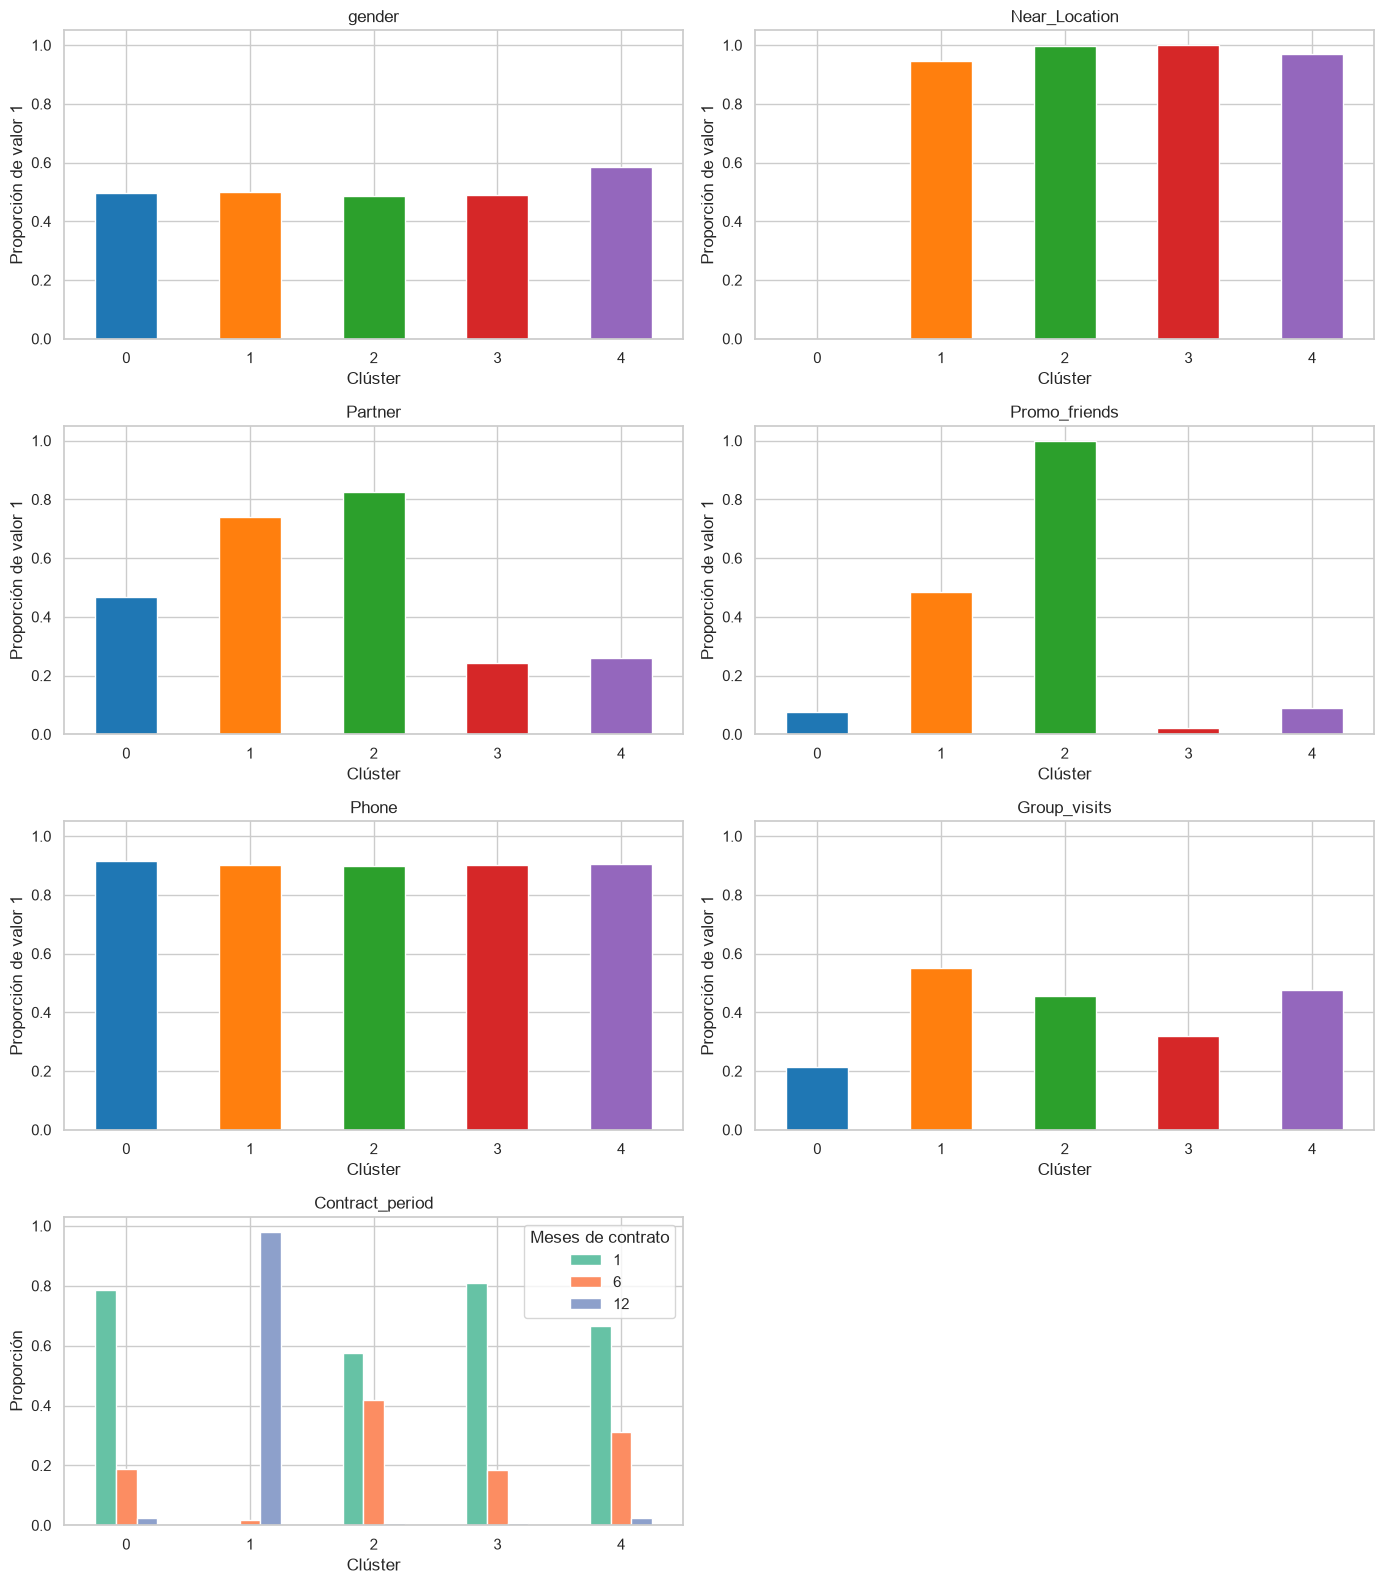

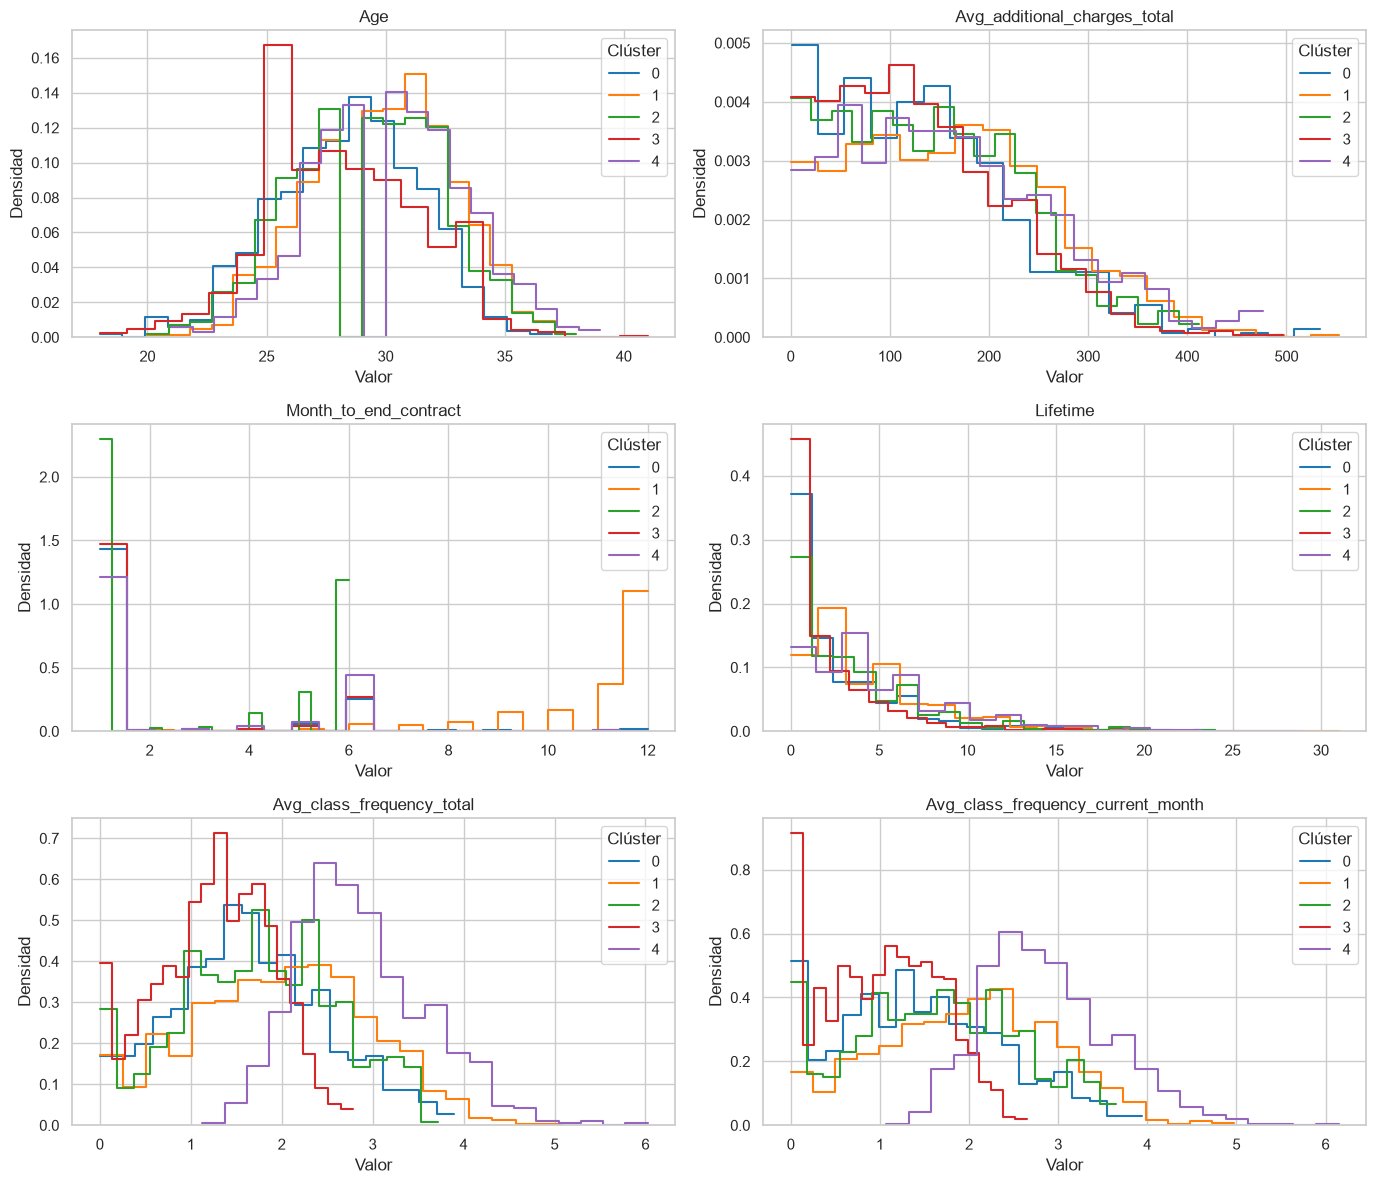

In [12]:
colores_cluster = sns.color_palette('tab10', 5)
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for ax, col in zip(axes.flat, binarias):
    medias_cluster[col].plot.bar(ax=ax, color=colores_cluster, rot=0)
    ax.set(title=col, xlabel='Clúster', ylabel='Proporción de valor 1', ylim=(0, 1.05))
contratos_cluster = pd.crosstab(gym_cluster['cluster'],
                              gym_cluster['Contract_period'], normalize='index')
contratos_cluster.plot.bar(ax=axes.flat[6], rot=0)
axes.flat[6].set(title='Contract_period', xlabel='Clúster', ylabel='Proporción')
axes.flat[6].legend(title='Meses de contrato')
axes.flat[7].set_visible(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, col in zip(axes.flat, continuas):
    for cluster in range(5):
        sns.histplot(gym_cluster.loc[gym_cluster['cluster'] == cluster, col],
                     bins=20, stat='density', element='step', fill=False,
                     color=colores_cluster[cluster], label=str(cluster), ax=ax)
    ax.set(title=col, xlabel='Valor', ylabel='Densidad')
    ax.legend(title='Clúster')
plt.tight_layout()
plt.show()

**Perfiles observados en las medias y distribuciones:**

- **Clúster 0: clientes alejados.** Ninguno vive o trabaja cerca. Tienen contratos de 2.21 meses en promedio, asistencia reciente de 1.47 visitas semanales y participación grupal del 21.51 %.
- **Clúster 1: contratos largos.** Duración media de 11.88 meses, 74.04 % de clientes de empresas asociadas y 55.13 % de participación grupal. La distribución de contratos se concentra en un año.
- **Clúster 2: clientes referidos.** El 100 % ingresó por la promoción de amigos y el 82.35 % pertenece a empresas asociadas. Su asistencia reciente media es de 1.64 visitas y su antigüedad, 3.74 meses.
- **Clúster 3: baja vinculación.** Viven o trabajan cerca, pero tienen poca asistencia reciente (1.03 visitas semanales), contratos cortos (1.99 meses) y baja antigüedad (2.39 meses). Solo el 2.08 % ingresó por recomendación.
- **Clúster 4: clientes activos.** Presentan la mayor asistencia reciente (2.88 visitas semanales) y antigüedad media (5.15 meses), con contratos de 2.81 meses en promedio.

Las distribuciones se solapan: los perfiles describen tendencias, no reglas aplicables a cada persona. Destacan las separaciones por cercanía, contrato y promoción. La estandarización de variables binarias también influye en estas separaciones.

### 4.4. Tasa de cancelación por clúster

Solo después de crear los segmentos se incorpora la cancelación para interpretarlos. Al ser binaria, la media de `Churn` es la tasa de cancelación. Se muestran también tamaños y cancelaciones para contextualizar las tasas.

,clientes,cancelaciones,tasa_cancelacion
cluster,,,
0,544,245,0.450
1,936,21,0.022
2,646,159,0.246
3,1107,583,0.527
4,767,53,0.069


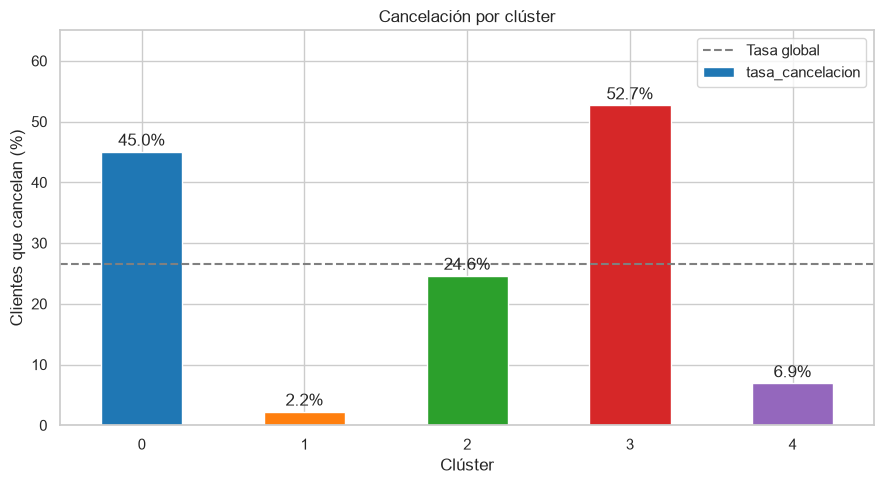

In [13]:
churn_cluster = gym_cluster.groupby('cluster')['Churn'].agg(
    clientes='size', cancelaciones='sum', tasa_cancelacion='mean'
)
display(churn_cluster)
ax = (churn_cluster['tasa_cancelacion'] * 100).plot.bar(
    figsize=(9, 5), color=colores_cluster, rot=0
)
ax.axhline(gym['Churn'].mean() * 100, color='gray', linestyle='--', label='Tasa global')
for i, valor in enumerate(churn_cluster['tasa_cancelacion'] * 100):
    ax.text(i, valor + 1, f'{valor:.1f}%', ha='center')
ax.set(title='Cancelación por clúster', xlabel='Clúster', ylabel='Clientes que cancelan (%)', ylim=(0, 65))
ax.legend()
plt.tight_layout()
plt.show()

Los segmentos de mayor riesgo son el **3 (52.66 %)** y el **0 (45.04 %)**, ambos por encima del 26.53 % global. Juntos reúnen 1,651 clientes y 828 de las 1,061 cancelaciones, aproximadamente el **78.04 %** del total.

Los clústeres **1 (2.24 %)** y **4 (6.91 %)** muestran mayor permanencia. Sus perfiles indican dos patrones: contratos largos y asistencia frecuente. El clúster **2 (24.61 %)** queda cerca, aunque por debajo, de la tasa global. Estas tasas describen los mismos clientes utilizados para segmentar; no son una evaluación predictiva fuera de muestra.

## 5. Conclusiones y recomendaciones

### Conclusiones

La cancelación afecta al **26.53 %** de los clientes. La menor antigüedad, la menor asistencia reciente y los contratos más cortos son señales destacadas de riesgo. Las actividades grupales, las empresas asociadas y las promociones de amigos presentan asociaciones con mayor permanencia, sin demostrar un efecto causal.

El **bosque aleatorio** logra el mejor resultado en la validación realizada, con **92.75 % de exactitud, 88.50 % de precisión y 83.49 % de recall**. Su ventaja sobre la regresión logística es pequeña. La segmentación permite distinguir a los clientes cercanos pero poco activos, los alejados, los referidos, los de contratos largos y los de alta asistencia.

### Cuatro recomendaciones de retención

1. **Acompañar el inicio y priorizar a los clientes poco activos.** Quienes cancelan tienen solo 0.99 meses de antigüedad media. Implementar una sesión de bienvenida, un plan de asistencia y seguimiento durante las primeras semanas. Priorizar el clúster 3, con 52.66 % de cancelación, usando las probabilidades del modelo para ordenar los contactos. Medir asistencia y retención al mes siguiente.

2. **Facilitar la asistencia de quienes viven o trabajan lejos.** El clúster 0 tiene 45.04 % de cancelación. Consultar barreras de traslado y horario, ofrecer horarios alternativos o acceso a otra sede si está disponible. Comparar su retención con la de un grupo similar sin la intervención para comprobar si la acción funciona.

3. **Probar invitaciones a actividades grupales y acompañamiento entre amigos.** La participación grupal es 46.41 % entre quienes permanecen y 26.86 % entre quienes cancelan. Ofrecer una clase de prueba y una reserva acompañada a clientes con poca participación. Evaluar asistencia y cancelación mediante una prueba controlada; la asociación observada no garantiza el efecto de la campaña.

4. **Ofrecer renovaciones adecuadas y mantener la actividad de los clientes leales.** El clúster 1, con contratos casi anuales, cancela un 2.24 %, y el clúster 4, con alta asistencia, un 6.91 %. Probar recordatorios antes del vencimiento y opciones de 6 o 12 meses para clientes satisfechos, junto con actividades que mantengan su rutina. Medir renovación y uso efectivo, sin asumir que alargar el contrato por sí solo genera lealtad.

### Alcance

El estudio utiliza una sola muestra mensual y una división aleatoria de validación. No permite probar causalidad ni estabilidad entre meses. Antes de desplegar una campaña, conviene validar con información posterior, revisar la disponibilidad temporal de las características y medir el efecto de las acciones con un grupo de comparación. Los números de clúster pueden cambiar entre implementaciones; lo relevante son sus perfiles y tasas.